# Employee Performance Analysis - Visualization
This notebook collects the main charts of the project: rating distribution, department-wise performance, important factors and model comparison.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

data = pd.read_csv('../../data/processed/cleaned_data.csv')
model = joblib.load('../models/random_forest_model.pkl')
columns = joblib.load('../models/model_columns.pkl')

## Distribution of Performance Ratings

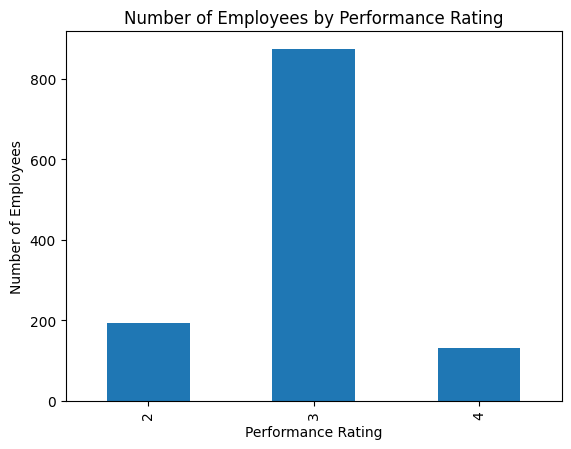

In [2]:
data['PerformanceRating'].value_counts().sort_index().plot(kind='bar')
plt.title('Number of Employees by Performance Rating')
plt.xlabel('Performance Rating')
plt.ylabel('Number of Employees')
plt.show()

## Department-wise Performance

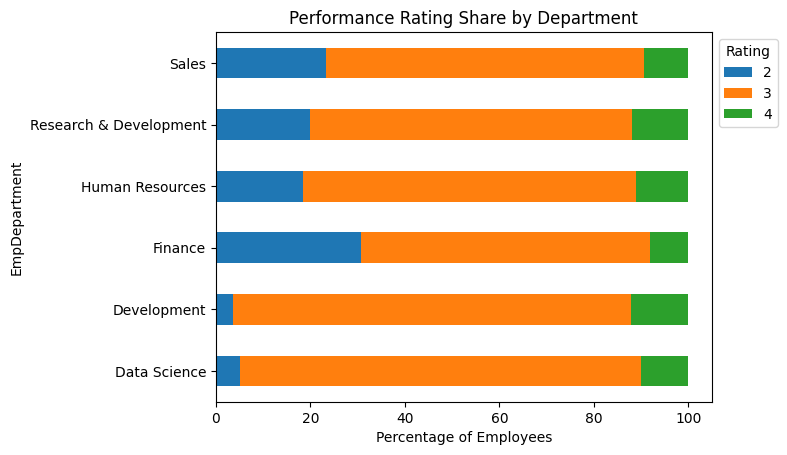

In [3]:
dept_percent = pd.crosstab(data['EmpDepartment'], data['PerformanceRating'], normalize='index') * 100
dept_percent.plot(kind='barh', stacked=True)
plt.title('Performance Rating Share by Department')
plt.xlabel('Percentage of Employees')
plt.legend(title='Rating', loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

## Most Important Factors

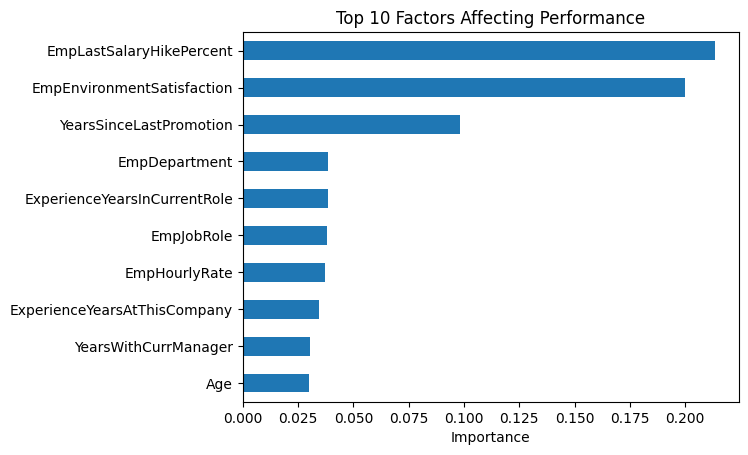

In [4]:
importance = pd.Series(model.feature_importances_, index=columns)
importance.sort_values().tail(10).plot(kind='barh')
plt.title('Top 10 Factors Affecting Performance')
plt.xlabel('Importance')
plt.show()

## Model Comparison

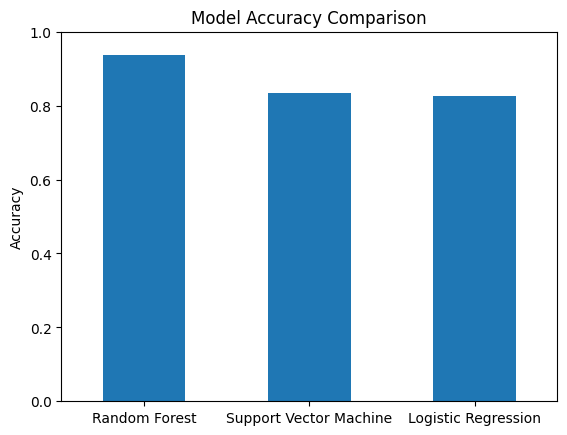

In [5]:
results = pd.Series({'Random Forest': 0.9375,
                     'Support Vector Machine': 0.8333,
                     'Logistic Regression': 0.8250})
results.plot(kind='bar')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

## Overtime and Performance

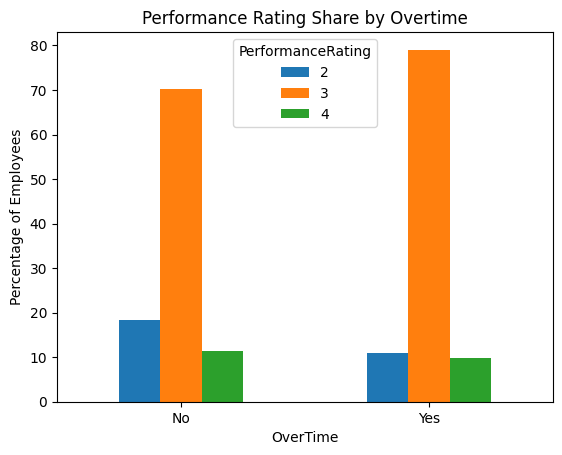

In [6]:
overtime_percent = pd.crosstab(data['OverTime'], data['PerformanceRating'], normalize='index') * 100
overtime_percent.plot(kind='bar')
plt.title('Performance Rating Share by Overtime')
plt.ylabel('Percentage of Employees')
plt.xticks(rotation=0)
plt.show()

In [7]:
overtime_percent.round(1)

PerformanceRating,2,3,4
OverTime,,,
No,18.3,70.2,11.5
Yes,11.0,79.0,9.9
